# 276. Paint Fence
https://leetcode.com/problems/paint-fence/

## Complexity Comparison

| Approach | Time | Space | Description |
|----------|------|-------|-------------|
| DP array | O(n) | O(n) | Track same/diff color counts |
| **DP two variables (Optimal)** | **O(n)** | **O(1)** | Only need previous two totals |

## Methodology

For each fence post, we can either paint it the same color as the previous post (only if the two before it were different) or a different color. Let `same` = ways where last two are same color, `diff` = ways where last two are different. For each new post: `new_same = diff`, `new_diff = (same + diff) * (k - 1)`. The total is `same + diff`.

## Solutions

### C#

In [ ]:
public class Solution {
    public int NumWays(int n, int k) {
        if (n == 0) return 0;
        if (n == 1) return k;
        int same = k, diff = k * (k - 1);
        for (int i = 3; i <= n; i++) {
            int prevDiff = diff;
            diff = (same + diff) * (k - 1);
            same = prevDiff;
        }
        return same + diff;
    }
}

### Python

In [ ]:
class Solution:
    def numWays(self, n: int, k: int) -> int:
        if n == 0: return 0
        if n == 1: return k
        same, diff = k, k * (k - 1)
        for _ in range(3, n + 1):
            same, diff = diff, (same + diff) * (k - 1)
        return same + diff

### Go

In [ ]:
func numWays(n int, k int) int {
    if n == 0 { return 0 }
    if n == 1 { return k }
    same, diff := k, k*(k-1)
    for i := 3; i <= n; i++ {
        same, diff = diff, (same+diff)*(k-1)
    }
    return same + diff
}

### Rust

In [ ]:
impl Solution {
    pub fn num_ways(n: i32, k: i32) -> i32 {
        if n == 0 { return 0; }
        if n == 1 { return k; }
        let (mut same, mut diff) = (k, k * (k - 1));
        for _ in 3..=n {
            let prev_diff = diff;
            diff = (same + diff) * (k - 1);
            same = prev_diff;
        }
        same + diff
    }
}

## Example Scenarios

### 1. Common Case — Three Posts, Two Colors
**Input:** `n = 3, k = 2`
The six valid colorings are RRB, RBR, RBB, BRR, BRB, BBR — no three posts in a row share a color. The DP tracks `same` and `diff` totals and returns $6$.

### 2. Slightly Complex — More Colors
**Input:** `n = 4, k = 3`
Starting from `same = 3, diff = 6`, each post applies `new_same = diff`, `new_diff = (same + diff)(k-1)`. After four posts the total is $66$.

### 3. Edge Case: Time Factor — Long Fence
**Input:** `n = 7, k = 2`
The recurrence runs once per post, so a 7-post fence takes 5 iterations past the base case: $O(n)$ time, yielding $42$.

### 4. Edge Case: Space Factor — Rolling Two Variables
**Input:** `n = 5, k = 2`
Only the previous `same` and `diff` are needed, so the whole DP uses $O(1)$ space no matter how long the fence. Result: $16$.

### 5. Almost-Impossible but Plausible — No Posts
**Input:** `n = 0, k = 5`
There is nothing to paint, so there are zero colorings regardless of the palette size: the guard returns $0$.


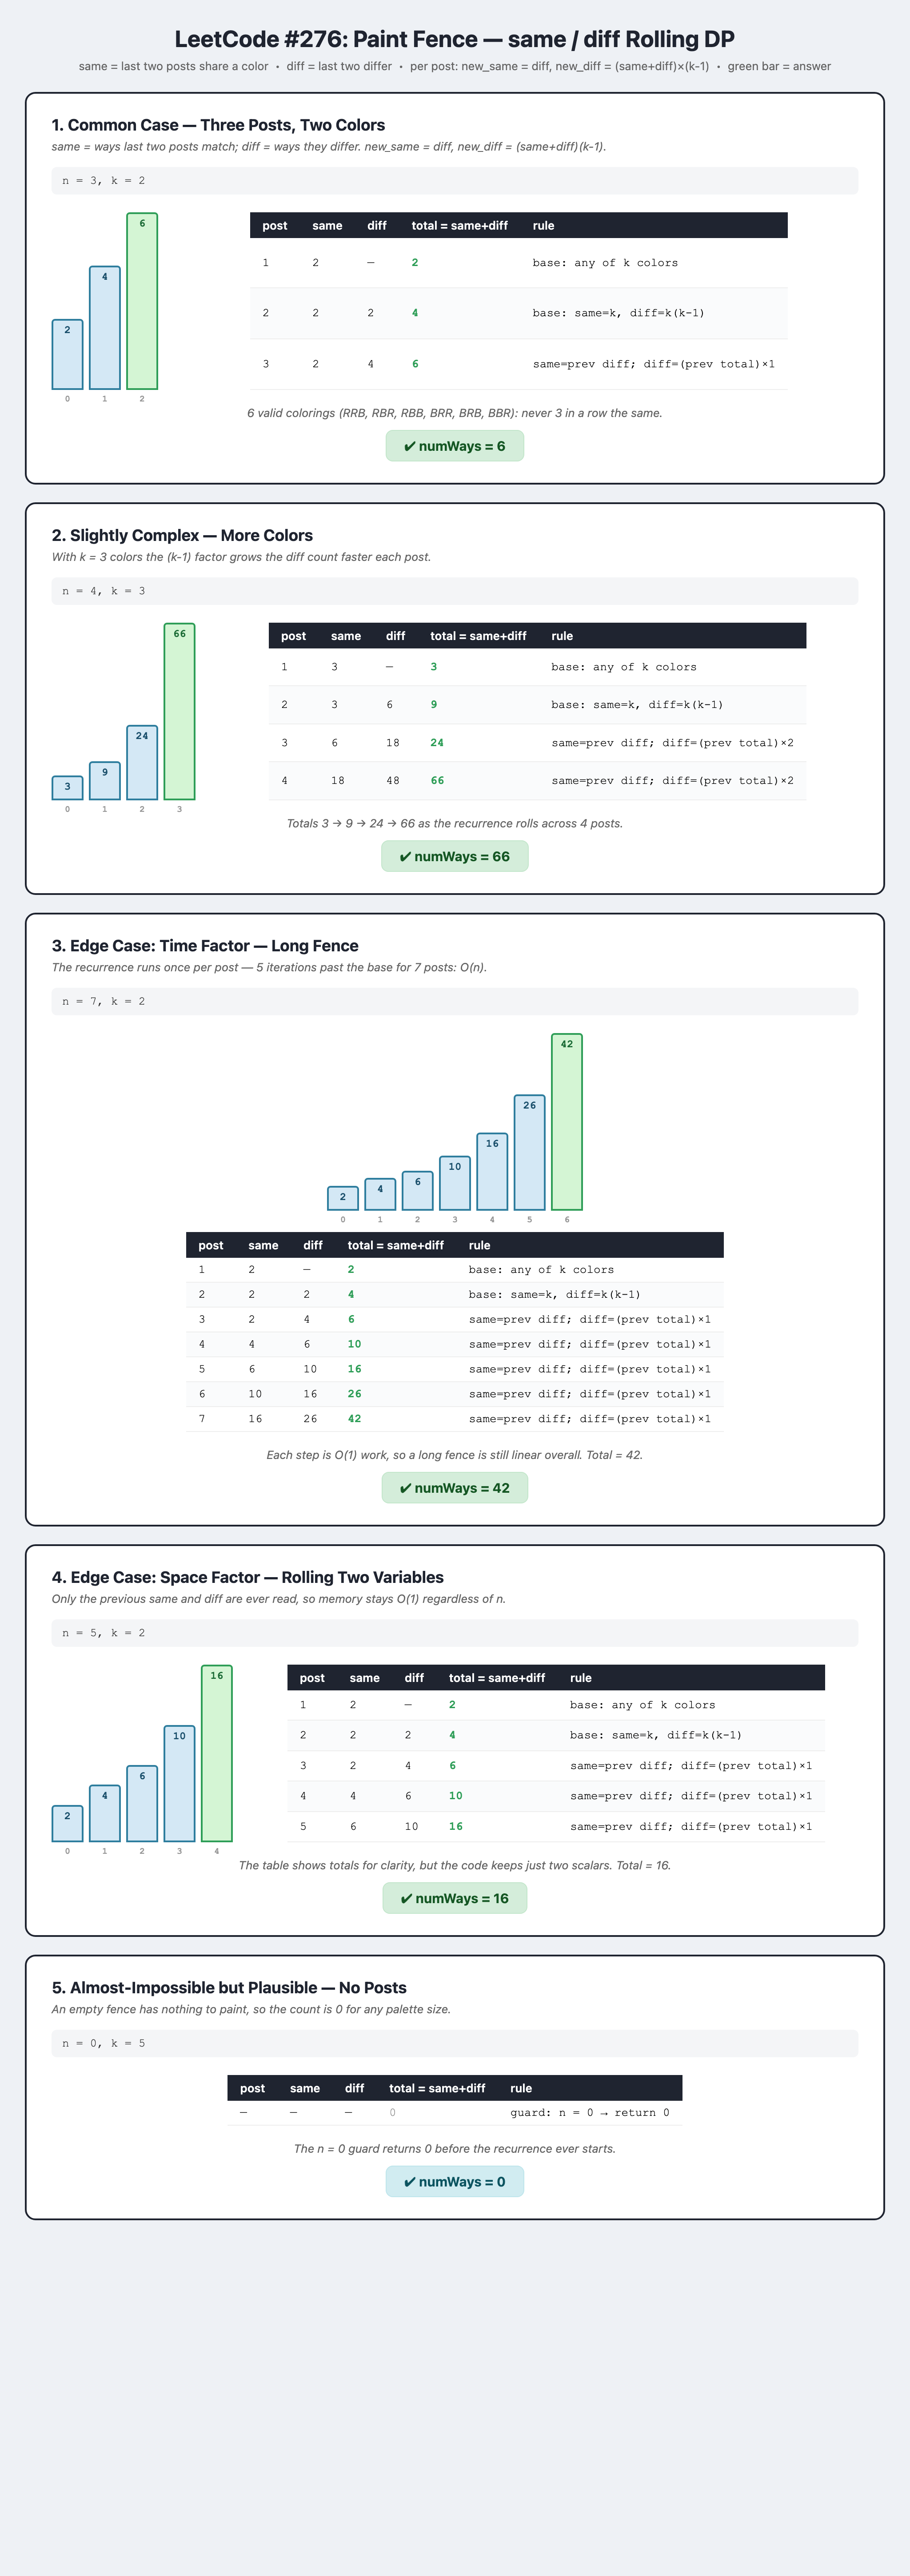